<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>

![](img/banner.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 120

# اعتبارسنجی خوشه‌بندی

**محمود امین‌طوسی، پاییز ۱۴۰۵**

گروه علوم کامپیوتر، دانشگاه فردوسی مشهد

این صفحه فصل 17 {cite}`zaki2020data` را دنبال می‌کند،
[Clustering Validation](https://www.cs.rpi.edu/~zaki/DMML/slides/pdf/ychap17.pdf).

## مقدمهٔ اعتبارسنجی خوشه‌بندی

اعتبارسنجی خوشه‌بندی کیفیت یک خوشه‌بندی را می‌سنجد. هر الگوریتم *یک* افراز از داده برمی‌گرداند؛
پرسش این است که آیا آن افراز خوب است، و دو افراز نامزد چگونه با هم مقایسه می‌شوند. سنجه‌ها در سه
خانواده می‌گنجند:

1. **سنجه‌های بیرونی**: از اطلاعات بیرونی، یعنی برچسب‌های حقیقت‌مبنا، استفاده می‌کنند.
2. **سنجه‌های درونی**: فقط از داده و نتیجهٔ خوشه‌بندی استفاده می‌کنند.
3. **سنجه‌های نسبی**: دو خوشه‌بندی از همان داده را بدون هیچ حقیقت‌مبنا با هم مقایسه می‌کنند.

**اهداف یادگیری.** در پایان باید بتوانید

1. جدول توافقی یک خوشه‌بندی را در برابر حقیقت‌مبنا بسازید و بخوانید؛
2. خلوص، دقت/بازآوری/F، تطبیق بیشینه، جاکارد، رند، ARI و NMI را حساب و تفسیر کنید و بگویید هر
   کدام چه چیزی را نادیده می‌گیرد؛
3. توضیح دهید چرا دقت (accuracy) روی برچسب‌های خوشه به کار نمی‌آید؛
4. سنجه‌های درونی (سیلوئت، SSE، شکاف) را به کار ببرید و بگویید چرا هیچ‌کدام تعداد «واقعی» خوشه‌ها
   را تعیین نمی‌کند؛
5. امتیاز تطبیق بیشینه را به‌عنوان یک مسئلهٔ تخصیص ببینید.

#### نشانه‌گذاری

زکی $r$ را برای تعداد خوشه‌ها و $k$ را برای تعداد دسته‌های حقیقت‌مبنا به کار می‌برد. این صفحه همان
حروف را نگه می‌دارد تا فرمول‌ها با کتاب بخوانند؛ دقت کنید که صفحه‌های k-means این درس $k$ را برای
تعداد *خوشه‌ها* به کار می‌برند. در همهٔ فرمول‌های زیر $n_{ij}$ تعداد نقطه‌های خوشهٔ $C_i$ را می‌شمارد
که به دستهٔ $T_j$ تعلق دارند، و $n$ تعداد نقطه‌ها است.

## سنجه‌های بیرونی

سنجه‌های بیرونی فرض می‌کنند خوشه‌بندی درست یا حقیقت‌مبنا *پیش از* ارزیابی معلوم است و همان برای
ارزیابی یک خوشه‌بندی به کار می‌رود.

بگذارید $\mathbf{D} = \{\mathbf{x}_i\}_{i=1}^n$ مجموعه‌داده‌ای با $n$ نقطه در فضای $d$-بعدی باشد که
به $k$ خوشه افراز شده است. و $y_i \in \{1, 2,\ldots , k\}$ برچسب یا عضویت حقیقت‌مبنای هر نقطه را
نشان دهد.

خوشه‌بندی حقیقت‌مبنا چنین داده شده است:

$$
\mathbf{T} = \left\{ T_1, T_2, \ldots, T_k \right\}
$$

که در آن خوشهٔ $T_{j}$ همهٔ نقطه‌های با برچسب $j$ را در بر دارد، یعنی

$$
T_{j} = \left\{ \mathbf{x}_i \in \mathbf{D} \mid y_i = j \right\}
$$

به $\mathbf{T}$ *افراز* حقیقت‌مبنا و به هر $T_i$ یک *قسمت* (دسته) می‌گوییم.

بگذارید $\mathbf{C} = \{C_1, \ldots, C_r\}$ یک خوشه‌بندی از همان مجموعه‌داده به $r$ خوشه باشد که با
یک الگوریتم خوشه‌بندی به دست آمده، و $\hat{y}_i \in \{1, 2, \ldots, r\}$ برچسب خوشه برای
$\mathbf{x}_i$.

سنجه‌های ارزیابی بیرونی می‌کوشند اندازهٔ این را بگیرند که نقطه‌های یک قسمت تا چه حد در یک خوشه
می‌افتند، و نقطه‌های قسمت‌های مختلف تا چه حد در خوشه‌های مختلف گروه می‌شوند.

همهٔ سنجه‌های بیرونی به **جدول توافقی** $r \times k$ یعنی $\mathbf{N}$ تکیه می‌کنند که از
خوشه‌بندی $\mathbf{C}$ و افراز حقیقت‌مبنای $\mathbf{T}$ برمی‌آید:

$$
\mathbf{N}(i,j) = n_{ij}  = \left| C_i \cap T_{j} \right|
$$

شمارش $n_{ij}$ تعداد نقطه‌های مشترک خوشهٔ $C_i$ و قسمت $T_{j}$ است.

بگذارید $n_{i} = |C_i|$ تعداد نقطه‌های خوشهٔ $C_i$ و $m_{j} = |T_{j}|$ تعداد نقطه‌های قسمت $T_{j}$
باشد. جدول توافقی را می‌توان در زمان $O(n)$ از $\mathbf{T}$ و $\mathbf{C}$ ساخت: برچسب قسمت و
خوشهٔ هر نقطه $\mathbf{x}_i \in \mathbf{D}$ یعنی $y_i$ و $\hat{y}_i$ بررسی و شمارندهٔ متناظر
$n_{\hat{y}_i,\,y_i}$ یک واحد زیاد می‌شود — شاخص اول برچسب خوشه و شاخص دوم برچسب دسته است، پس
سطرهای $\mathbf{N}$ خوشه‌ها و ستون‌هایش دسته‌ها هستند.

In [2]:
import pandas as pd

def display_contingency_table_pandas(table, class_names=None, cluster_names=None):
    r, k = table.shape
    if class_names is None:
        class_names = [f"Class {j}" for j in range(k)]
    if cluster_names is None:
        subscript = "₀₁₂₃₄₅₆₇₈₉"
        cluster_names = [f"C{subscript[i]}" for i in range(r)]

    df = pd.DataFrame(table, index=cluster_names, columns=class_names)
    display(df.style
              .set_properties(**{'text-align': 'center'})
              .set_table_styles([
                  {'selector': 'th',
                   'props': [('text-align', 'center'),
                             ('background-color', '#f2f2f2'),
                             ('border', '1px solid #ccc')]},
                  {'selector': 'td',
                   'props': [('border', '1px solid #ccc')]},
              ]))

In [3]:
import numpy as np


def compute_contingency_table(cluster_labels, true_labels):
    """Contingency table of a clustering against the ground truth.

    Returns an ``(r, k)`` integer matrix: rows index clusters, columns index classes,
    so ``table[i, j]`` is the number of points of cluster ``i`` in class ``j``.
    """
    unique_classes, class_map = np.unique(true_labels, return_inverse=True)
    unique_clusters, cluster_map = np.unique(cluster_labels, return_inverse=True)

    table = np.zeros((len(unique_clusters), len(unique_classes)), dtype=int)
    np.add.at(table, (cluster_map, class_map), 1)
    return table

### نخستین نقطهٔ مرجع: یک خوشه‌بندی کامل

پیش از دیدن هر چیزی که غلط پیش می‌رود، به یک خط پایه نیاز داریم. جدول زیر وقتی به دست می‌آید که هر
خوشه دقیقاً با یک دستهٔ حقیقت‌مبنا بخواند. ماتریس توافقی **قطری** است: هر درایهٔ بیرون قطر صفر است.

این تنها حالتی است که مقدار «آرمانی» هر سنجهٔ بیرونی معقول (1 برای خلوص، NMI و ARI) در آن به دست
می‌آید. هر مثال دیگر این صفحه باید با همین خط پایه سنجیده شود.

In [4]:
# Example A — perfect clustering
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,3,0,0
C₁,0,3,0
C₂,0,0,3


### یک خوشه‌بندی خوب با خطای کوچک و متقارن

بیشتر خوشه‌بندی‌های واقعی تقریباً درست‌اند. اینجا `C₀` هنوز کاملاً خالص است، ولی `C₁` و `C₂` **هر
کدام یک نقطه را با هم عوض کرده‌اند**: یک نقطه از دستهٔ `T₁` در `C₂` افتاده و یکی از `T₂` در `C₁`.

جدول تقریباً قطری است، پس خلوص، NMI و ARI همه نزدیک به 1 ولی کمی کمتر خواهند بود. این همان حالت
معمول «کمی ناقص» است که بیشتر الگوریتم‌های عملی تولید می‌کنند.

In [5]:
# Example B — almost perfect, one swap
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 1, 1, 2, 2, 2, 1])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,3,0,0
C₁,0,2,1
C₂,0,1,2


### شناسه‌های خوشه برچسب دلخواه‌اند، نه ترتیب

افراز زیر **دقیقاً همان** مثال B است؛ فقط شناسه‌های خوشه‌ها جای هم شده‌اند. `C₁` در این مثال همان
است که پیش‌تر `C₂` بود و برعکس.

جدول همان جدول B با سطرهای جابه‌جا شده است — و هر سنجهٔ بیرونی همان مقدار عددی را می‌دهد. همین
دلیل است که همهٔ سنجه‌های بیرونی باید **نسبت به جایگشت شناسه‌های خوشه ناوردا** باشند: عددهای `0`،
`1`، `2` که `KMeans.labels_` برمی‌گرداند فقط نام‌اند، نه رتبه.

In [6]:
# Example C — same partition as B, cluster ids relabelled
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([1, 1, 1, 2, 2, 0, 0, 0, 2])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,0,1,2
C₁,3,0,0
C₂,0,2,1


### یک خوشه‌بندی ضعیف با پخش متقارن

دیگر خوشه‌بندی به حقیقت‌مبنا نزدیک نیست. هر خوشه نقطه‌هایی از دو دستهٔ مختلف دارد و هر دسته میان دو
خوشه تقسیم شده است. جدول در هر سطر و هر ستون چند درایهٔ ناصفر دارد، ولی هیچ سطر یا ستونی «خالص»
نیست.

خلوص حدود 0.5 خواهد بود و NMI و ARI به‌روشنی زیر 1. توجه کنید که هنوز **اندکی** سیگنال هست:
درایه‌های قطری صفر نیستند، پس خوشه‌بندی تصادفی نیست — فقط ضعیف است.

In [7]:
# Example D — weak clustering, scattered table
true_labels    = np.array([0, 0, 1, 1, 2, 2])
cluster_labels = np.array([0, 1, 1, 2, 2, 0])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,1,0,1
C₁,1,1,0
C₂,0,1,1


### یک حالت فریبنده: جدول کاملاً یکنواخت

این مثال جدول توافقی‌ای دارد که **همهٔ درایه‌هایش دقیقاً برابرند**. هر خوشه یک نقطه از هر دسته دارد
و هر دسته به‌طور یکنواخت روی همهٔ خوشه‌ها پخش شده است.

این آموزنده‌ترین حالت صفحه است. جدول مرتب و منظم به نظر می‌رسد، ولی **هیچ اطلاعاتی** ندارد: دانستن
اینکه نقطه در کدام خوشه افتاده چیزی دربارهٔ دستهٔ واقعی‌اش نمی‌گوید.

خلوص دقیقاً `1/3` است و NMI و ARI دقیقاً 0 — همان مقدارهایی که یک تخصیص کاملاً تصادفی می‌دهد.
منظم بودن جدول با سودمند بودن خوشه‌بندی یکی نیست.

In [8]:
# Example E — deceptive, uniform contingency table
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 1, 2, 1, 2, 0, 2, 0, 1])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,1,1,1
C₁,1,1,1
C₂,1,1,1


### وقتی تعداد خوشه‌ها با تعداد دسته‌ها فرق دارد

همهٔ مثال‌های تا اینجا $k = r$ داشتند: به تعداد دسته‌های حقیقت‌مبنا خوشه. ولی k-means با یک `K`
ثابتی اجرا می‌شود که کاربر انتخاب می‌کند و تضمینی نیست که `K` با تعداد دسته‌های واقعی بخواند.

در مثال زیر حقیقت‌مبنا **سه** دسته دارد ولی الگوریتم **چهار** خوشه تولید کرده است — یکی از دسته‌ها
را به دو تکه *بیش‌افراز* کرده. پس جدول توافقی مربعی نیست و هیچ «دقت» ساده‌ای حساب‌شدنی نیست:
تناظر یک‌به‌یک میان شناسه‌های خوشه و دسته وجود ندارد.

خلوص هنوز حساب‌شدنی و معنادار است: برای هر خوشه می‌پرسد چقدر خالص است و بعد میانگین می‌گیرد. ولی
یک خوشه‌بندی بیش‌افراز خلوصی به‌طور مشکوک بالا می‌گیرد، چون ساختن خوشه‌های کوچک خالص آسان است.
NMI و ARI این را درست جریمه می‌کنند، و همین دقیقاً دلیل ترجیحشان در عمل است وقتی `K` از پیش معلوم
نیست.

In [9]:
# Example F — k = 4 clusters vs r = 3 classes (over-segmentation)
# The 3 points of class T₀ are split across two clusters: C₀ and C₃.
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 3, 1, 1, 1, 2, 2, 2])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,2,0,0
C₁,0,3,0
C₂,0,0,3
C₃,1,0,0


### حالت مقابل: خوشه‌های خیلی کم

اینجا وضعیت برعکس است: الگوریتم با $K = 2$ اجرا شده ولی **سه** دستهٔ واقعی وجود دارد. دو تا از
آن‌ها در یک خوشه ادغام شده‌اند.

جدول توافقی اکنون ماتریسی $2 \times 3$ است، با سطری که نقطه‌هایی از دو دستهٔ مختلف دارد. خلوص
فوراً افت می‌کند، چون آن سطر دو درایهٔ ناصفر با اندازهٔ قابل مقایسه دارد. کم‌افرازی بسیار سخت‌تر از
بیش‌افرازی پنهان می‌شود.

In [10]:
# Example G — k = 2 clusters vs r = 3 classes (under-segmentation)
# Classes T₀ and T₁ have been merged into a single cluster C₀.
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,3,3,0
C₁,0,0,3


## محاسبهٔ کارای جدول توافقی با `np.add.at`

در پیاده‌سازی سنجه‌های اعتبارسنجی خوشه‌بندی، ساختن **جدول توافقی** گامی کلیدی است. یک راه کارا
برای این کار در **NumPy** استفاده از `np.add.at` است. این تابع **جمع‌شدن درست شمارنده‌ها** را وقتی
شاخص‌های تکراری وجود دارد تضمین می‌کند.

### چرا `np.add.at`؟

برخلاف **افزایش شاخص‌محور** ساده، مثل:
```python
contingency_table[cluster_map, class_map] += 1
```
**نمایه‌گذاری فانتزی** NumPy یک کپی موقت می‌سازد، یعنی به‌روزرسانی شاخص‌های تکراری ممکن است درست
جمع نشود. در عوض `np.add.at` تغییر درجا را تضمین می‌کند:

```python
np.add.at(contingency_table, (cluster_map, class_map), 1)
```

### مثال: تفاوت نمایه‌گذاری مستقیم و `np.add.at`

مثالی که نشان می‌دهد `np.add.at` شاخص‌های تکراری را درست مدیریت می‌کند در حالی که نمایه‌گذاری
مستقیم ممکن است شکست بخورد:

In [11]:
import numpy as np

def compute_contingency_table_direct(cluster_labels, true_labels):
    """Same table, built with direct indexed incrementation."""
    unique_classes, class_map = np.unique(true_labels, return_inverse=True)
    unique_clusters, cluster_map = np.unique(cluster_labels, return_inverse=True)

    table = np.zeros((len(unique_clusters), len(unique_classes)), dtype=int)
    table[cluster_map, class_map] += 1  # a temporary copy is written back: duplicates are lost
    return table

In [12]:
import numpy as np

true_labels    = np.array([0, 0, 1, 1, 1, 2, 2, 2, 2])
cluster_labels = np.array([0, 1, 1, 1, 1, 2, 2, 2, 2])

contingency_table_at = compute_contingency_table(cluster_labels, true_labels)
contingency_table_direct = compute_contingency_table_direct(cluster_labels, true_labels)

print("Using direct indexing:")
display_contingency_table_pandas(contingency_table_direct)

print("\nUsing np.add.at:")
display_contingency_table_pandas(contingency_table_at)

Using direct indexing:


,Class 0,Class 1,Class 2
C₀,1,0,0
C₁,1,1,0
C₂,0,0,1



Using np.add.at:


,Class 0,Class 1,Class 2
C₀,1,0,0
C₁,1,3,0
C₂,0,0,4


### 1. خلوص

خلوص می‌سنجد هر خوشه چقدر «خالص» است، با کسر نقطه‌های دستهٔ غالب:

$$
\text{purity} = \frac{1}{n}\sum_{i=1}^r \max_{j=1}^k \{n_{ij}\}
$$

که در آن:
- $ n $ = تعداد کل نقطه‌ها
- $ r $ = تعداد خوشه‌ها
- $ k $ = تعداد دسته‌های واقعی
- $ n_{ij} $ = تعداد نقطه‌های خوشهٔ $ i $ از دستهٔ $ j $

In [13]:
def purity_score(cluster_labels, true_labels):
    contingency_matrix = compute_contingency_table(cluster_labels, true_labels)
    return np.sum(np.amax(contingency_matrix, axis=1)) / np.sum(contingency_matrix)

مثالی را بررسی کنیم که در آن **خلوص بالا** به دست می‌آید و مطمئن می‌شویم خوشه‌بندی با افراز
حقیقت‌مبنا هم‌تراز است.

### **دادهٔ نمونه**
فرض کنید این خوشه‌بندی و برچسب‌های حقیقت‌مبنا را داریم:
```python
true_labels    = np.array([0, 0, 1, 1, 1, 2])
cluster_labels = np.array([0, 0, 1, 1, 2, 2])
```
اینجا هر خوشه با یک دستهٔ واقعی بهتر می‌خواند.

### **محاسبهٔ جدول توافقی**
با تابع `compute_contingency_table` به این جدول می‌رسیم:

|   | دستهٔ 0 | دستهٔ 1 | دستهٔ 2 |
|---|--------|--------|--------|
| C₀ | 2 | 0 | 0 |
| C₁ | 0 | 2 | 0 |
| C₂ | 0 | 1 | 1 |

### **محاسبه‌های میانی**
**گام 1:** بیشینهٔ هر سطر را بیابید:
- `max(C₀) = 2`  
- `max(C₁) = 2`  
- `max(C₂) = 1`  

**گام 2:** مقدارهای بیشینه را جمع بزنید:
$ \sum \max(n_{ij}) = 2 + 2 + 1 = 5 $

**گام 3:** خلوص را حساب کنید:
$
\text{Purity} = \frac{\sum \max(n_{ij})}{\sum n_{ij}} = \frac{5}{6} \approx 0.833
$

In [14]:
true_labels = np.array([0, 0, 1, 1, 1, 2])
cluster_labels = np.array([0, 0, 1, 1, 2, 2])

score = purity_score(cluster_labels, true_labels)
print(f"Purity Score: {score:.3f}")  # Expected output: 0.833

Purity Score: 0.833


**خلوص نسبت به برچسب‌های خوشه ناوردا است**، یعنی تغییر نام خوشه‌ها امتیاز را عوض نمی‌کند تا
وقتی خود تخصیص ثابت بماند.

همان خوشه‌بندی پیشین را بگیرید ولی **برچسب‌های خوشه را جابه‌جا کنید** (مثلاً نام C₀ را به C₂، C₁ را
به C₀ و C₂ را به C₁ تغییر دهید):

In [15]:
import numpy as np

# Original clustering labels
true_labels            = np.array([0, 0, 1, 1, 1, 2])
cluster_labels         = np.array([0, 0, 1, 1, 2, 2])
shifted_cluster_labels = np.array([2, 2, 0, 0, 1, 1]) # Shifted cluster labels (mapping: 0 → 2, 1 → 0, 2 → 1)

# Compute purity scores for both cases
original_purity = purity_score(cluster_labels, true_labels)
shifted_purity = purity_score(shifted_cluster_labels, true_labels)

print(f"Original Purity: {original_purity:.3f}")  # Expected output: 0.833
print(f"Shifted Labels Purity: {shifted_purity:.3f}")  # Expected output: 0.833 (same!)

Original Purity: 0.833
Shifted Labels Purity: 0.833


**چرا خلوص ثابت می‌ماند؟**
- **تناظر میان خوشه‌ها و قسمت‌های حقیقت‌مبنا عوض نشده**، فقط برچسب‌هایشان.
- چون خلوص فقط به **اینکه خوشه‌ها چقدر با قسمت‌های حقیقت‌مبنا می‌خوانند** بستگی دارد، تغییر نام
  خوشه‌ها در محاسبهٔ خلوص **اثری ندارد**.

### 2. دقت، بازآوری و F-measure

برای هر خوشهٔ $ C_i $:

- **دقت**: کسر نقطه‌های خوشه که از دستهٔ غالب‌اند
- **بازآوری**: کسر نقطه‌های دسته که در خوشه یافت شده‌اند

![](img/Precisionrecall.png)

### دقت
برای خوشهٔ $C_i$، بگذارید $j_i$ قسمتی را نشان دهد که بیشترین تعداد نقطه از $C_i$ را دارد،

$$
j_i = \arg\max_{j=1}^{k} \left\{ n_{ij} \right\}
$$

یعنی شاخص بزرگترین درایهٔ سطر $i$ در جدول توافقی. دقت خوشهٔ $C_i$ همان خلوص آن است:

$$
\mathit{prec}_i = \frac{1}{n_{i}}\max_{j=1}^k \left\{ n_{ij} \right\} =
\frac{n_{ij_i}}{n_i}
$$

### بازآوری
بازآوری خوشهٔ $C_i$ چنین تعریف می‌شود:

$$
\mathit{recall}_i = \frac{n_{ij_i}}{|\mathbf{T}_{j_i}|} =\frac{n_{ij_i}}{m_{j_i}}
$$

که $m_{j_i} = |\mathbf{T}_{j_i}|$.

### F-measure
F-measure میانگین هارمونیک دقت و بازآوری هر $C_i$ است:

$$
F_i = \frac{2}{\frac{1}{\mathit{prec}_i} + \frac{1}{\mathit{recall}_i}} =
\frac{2 \cdot \mathit{prec}_i \cdot \mathit{recall}_i}{\mathit{prec}_i + \mathit{recall}_i} =
\frac{2 \; n_{ij_i}}{n_{i} + m_{j_i}}
$$

**F-measure** برای خوشه‌بندی $\mathbf{C}$ میانگین مقادیر F خوشه‌ها است:

$$
F = \frac{1}{r} \sum_{i=1}^r F_i
$$

### 3. تطبیق بیشینه

بهترین تناظر میان خوشه‌ها و دسته‌های واقعی را می‌یابد تا هم‌پوشانی بیشینه شود:

$$
\text{match} = \frac{1}{n}\max_M \sum_{(i,j)\in M} n_{ij}
$$

که $ M $ یک تطبیق میان خوشه‌ها و دسته‌ها است.

**تطبیق با وزن بیشینه** (به پیروی از {cite}`zaki2020data`)

بگذارید $G$ گرافی دوبخشی روی مجموعهٔ رأس $V = \mathbf{C} \cup \mathbf{T}$ باشد و مجموعهٔ یال‌ها
$E = \{ (C_i, T_{j}) \}$ با وزن یال $w(C_i,T_{j}) = n_{ij}$. یک **تطبیق** $M$ در $G$ زیرمجموعه‌ای از
$E$ است که یال‌های $M$ دوبه‌دو مجاور نباشند، یعنی رأس مشترک نداشته باشند.

تطبیق با وزن بیشینه در $G$ چنین است:

$$
\mathit{match} = \max_{M} \left\{ \frac{w(M)}{n} \right\}
$$

که $w(M)$ مجموع وزن همهٔ یال‌های تطبیق $M$ است، $w(M) = \sum_{e \in M} w(e)$.

### مثال تطبیق بیشینه (تفسیر گراف دوبخشی)

**سناریو**: فرض کنید 10 میوه را در 3 خوشه خوشه‌بندی کرده‌ایم و دسته‌های واقعی آن‌ها را می‌دانیم:

```
دسته‌های واقعی (T₁=سیب، T₂=پرتقال، T₃=موز):
T₁: apple1, apple2, apple3, apple4
T₂: orange1, orange2, orange3
T₃: banana1, banana2, banana3

تخصیص خوشه‌ها (C₁, C₂, C₃):
C₁: [apple1, apple2, banana1]
C₂: [orange1, orange2, apple3] 
C₃: [banana2, banana3, orange3, apple4]

```

### جدول توافقی

|   | سیب (T₁) | پرتقال (T₂) | موز (T₃) | مجموع (nᵢ) |
|---|------------|-------------|-------------|-------------|
| C₁ (apple1, apple2, banana1) | 2 | 0 | 1 | 3 |
| C₂ (orange1, orange2, apple3) | 1 | 2 | 0 | 3 |
| C₃ (banana2, banana3, orange3, apple4) | 1 | 1 | 2 | 4 |
| **مجموع (mⱼ)** | 4 | 3 | 3 | **n = 10** |


**گام 1: ساختن گراف دوبخشی**

میان خوشه‌ها و دسته‌ها یال‌هایی با وزن برابر هم‌پوشانی می‌سازیم:

```
خوشه‌ها          دسته‌ها
   C₁ ------------- T₁ (weight=2: apple1,apple2)
      \------------ T₃ (weight=1: banana1)
   C₂ ------------- T₁ (weight=1: apple3)
      \------------ T₂ (weight=2: orange1,orange2)
   C₃ ------------- T₁ (weight=1: apple4)
      \------------ T₂ (weight=1: orange3)
      \------------ T₃ (weight=2: banana2,banana3)
```

**گام 2: یافتن تطبیق با وزن بیشینه**

می‌خواهیم هر خوشه را حداکثر به یک دسته (و برعکس) نسبت دهیم تا وزن کل بیشینه شود:

گزینه‌های ممکن:
1. تطبیق C₁-T₁ (2)، C₂-T₂ (2)، C₃-T₃ (2) $\rightarrow$ وزن کل = 6
2. تطبیق C₁-T₃ (1)، C₂-T₂ (2)، C₃-T₁ (1) $\rightarrow$ وزن کل = 4

گزینهٔ اول تطبیق با وزن بیشینه را می‌دهد.

**گام 3: محاسبهٔ امتیاز تطبیق بیشینه**

$$
\text{match} = \frac{\text{Total matched weight}}{n} = \frac{2+2+2}{10} = 0.6
$$

In [16]:
import numpy as np
from scipy.optimize import linear_sum_assignment

# Define contingency table
contingency = np.array([
    [2, 0, 1],  # C₁: 2 apples, 0 oranges, 1 banana
    [1, 2, 0],  # C₂: 1 apple, 2 oranges, 0 bananas
    [1, 1, 2]   # C₃: 1 apple, 1 orange, 2 bananas
])

# Find optimal matching
row_ind, col_ind = linear_sum_assignment(contingency, maximize=True)

# Perform indexing correctly
max_weight = contingency[row_ind, col_ind].sum()

print(f"Optimal matching: {list(zip(row_ind, col_ind))}")
print(f"Max weight: {max_weight}")

# Optimal matching: [(0, 0), (1, 1), (2, 2)]  # C₁-T₁, C₂-T₂, C₃-T₃

Optimal matching: [(np.int64(0), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(2))]
Max weight: 6


### مثال 17.1: خوشه‌بندی خوب در برابر بد روی دادهٔ Iris

دو خوشه‌بندی مختلف از مجموعه‌دادهٔ Iris را با مؤلفه‌های اصلی بررسی کنیم:

#### نتایج خوشه‌بندی خوب:

![](img/Zaki-Chap17-Good-Clustering.png)

### جدول توافقی

|   | iris-setosa | iris-versicolor | iris-virginica | مجموع (n_i) |
|---|------------|----------------|---------------|-------------|
| C₁ (مربع‌ها)  | 0  | 47  | 14  | 61  |
| C₂ (دایره‌ها)  | 50 | 0   | 0   | 50  |
| C₃ (مثلث‌ها) | 0  | 3   | 36  | 39  |
| **مجموع (m_j)** | 50 | 50  | 50  | **n = 150** |

**خلوص:** 0.887  
**تطبیق:** 0.887  
**F:** 0.885  

#### نتایج خوشه‌بندی بد:

![](img/Zaki-Chap17-Bad-Clustering.png)

### جدول توافقی

|   | iris-setosa | iris-versicolor | iris-virginica | مجموع (n_i) |
|---|------------|----------------|---------------|-------------|
| C₁ (مربع‌ها)  | 30  | 0   | 0   | 30  |
| C₂ (دایره‌ها)  | 20  | 4   | 0   | 24  |
| C₃ (مثلث‌ها) | 0  | 46  | 50  | 96  |
| **مجموع (m_j)** | 50 | 50  | 50  | **n = 150** |

**خلوص:** 0.667  
**تطبیق:** 0.560  
**F:** 0.658

بیشینه‌های سطرها $30+20+50=100$ است، پس خلوص $=100/150=0.667$. تطبیق بیشینه $C_1$–setosa (30)،
$C_2$–versicolor (4) و $C_3$–virginica (50) را جفت می‌کند، پس تطبیق $=84/150=0.560$. خلوص و
تطبیق اینجا فرق دارند چون خلوص می‌تواند دو خوشه را به یک دسته نسبت دهد ولی تطبیق نمی‌تواند.

### 4. سنجه‌های دوبه‌دو

نخست چند کمیت کلیدی به کار رفته در سنجه‌های بیرونی را تعریف کنیم:

- **TP (مثبت‌های درست)**: جفت‌هایی در یک خوشه و یک قسمت واقعی
- **FP (مثبت‌های نادرست)**: جفت‌هایی در یک خوشه ولی قسمت‌های متفاوت
- **TN (منفی‌های درست)**: جفت‌هایی در خوشه‌های متفاوت و قسمت‌های متفاوت
- **FN (منفی‌های نادرست)**: جفت‌هایی در خوشه‌های متفاوت ولی یک قسمت

با خوشه‌بندی $\mathbf{C}$ و افراز حقیقت‌مبنای $\mathbf{T}$، بگذارید $\mathbf{x}_i, \mathbf{x}_{j} \in \mathbf{D}$ دو نقطهٔ دلخواه با $i \ne j$ باشند. $y_i$ برچسب قسمت واقعی و $\hat{y}_i$ برچسب خوشهٔ نقطهٔ $\mathbf{x}_i$ را نشان دهد.

اگر $\mathbf{x}_i$ و $\mathbf{x}_{j}$ در یک خوشه باشند، یعنی $\hat{y}_i = \hat{y}_{j}$، آن را رویدادی *مثبت* می‌نامیم، و اگر در یک خوشه نباشند، یعنی $\hat{y}_i \ne \hat{y}_{j}$، رویدادی *منفی*. بسته به توافق یا نبود توافق میان برچسب‌های خوشه و برچسب‌های قسمت، چهار حالت داریم:

 **مثبت‌های درست (TP)**  
$\mathbf{x}_i$ و $\mathbf{x}_{j}$ در $\mathbf{T}$ در یک قسمت‌اند و در $\mathbf{C}$ هم در یک خوشه. تعداد جفت‌های مثبت درست:

$$
\mathit{TP} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i = y_{j}
\text{ and } \hat{y}_i = \hat{y}_{j} \}\bigr|
$$

 **منفی‌های نادرست (FN)**  
$\mathbf{x}_i$ و $\mathbf{x}_{j}$ در $\mathbf{T}$ در یک قسمت‌اند ولی در $\mathbf{C}$ در یک خوشه نیستند. تعداد جفت‌های منفی نادرست:

$$
\mathit{FN} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i = y_{j}
\text{ and } \hat{y}_i \ne \hat{y}_{j} \}\bigr|
$$



 **مثبت‌های نادرست (FP)**  
$\mathbf{x}_i$ و $\mathbf{x}_{j}$ در $\mathbf{T}$ در یک قسمت نیستند ولی در $\mathbf{C}$ در یک خوشه‌اند. تعداد جفت‌های مثبت نادرست:

$$
\mathit{FP} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i \ne y_{j}
\text{ and } \hat{y}_i = \hat{y}_{j} \}\bigr|
$$

 **منفی‌های درست (TN)**  
$\mathbf{x}_i$ و $\mathbf{x}_{j}$ نه در $\mathbf{T}$ در یک قسمت‌اند و نه در $\mathbf{C}$ در یک خوشه. تعداد این جفت‌ها:

$$
\mathit{TN} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i \ne y_{j}
\text{ and } \hat{y}_i \ne \hat{y}_{j} \}\bigr|
$$

### نمای دوبه‌دو از سنجه‌های بیرونی

جاکارد و رند هر دو مسئلهٔ خوشه‌بندی را جور دیگری از جدول توافقی می‌بینند: به‌جای مقایسهٔ شناسه‌های
خوشه با شناسه‌های دسته، پرسشی دربارهٔ هر **جفت نقطه** می‌پرسند.

برای جفت `(i, j)` می‌توان دو پرسش بله/خیر پرسید:

* آیا `i` و `j` در یک دستهٔ حقیقت‌مبنا هستند؟
* آیا `i` و `j` در یک خوشه هستند؟

چهار حالت ممکن است:

|                        | یک خوشه   | خوشه‌های مختلف |
|:----------------------:|:--------------:|:-----------------:|
| **یک دسته**         | TP (مثبت درست)  | FN (منفی نادرست) |
| **دسته‌های مختلف**    | FP (مثبت نادرست) | TN (منفی درست)  |

* **TP** — جفتی که در حقیقت‌مبنا **با هم** و در خوشه‌بندی هم **با هم** است.
* **TN** — جفتی که در حقیقت‌مبنا **جدا** و در خوشه‌بندی هم **جدا** است.
* **FP** — جفتی که در حقیقت‌مبنا جدا است ولی خوشه‌بندی آن را **ادغام** کرده.
* **FN** — جفتی که در حقیقت‌مبنا با هم است ولی خوشه‌بندی آن را **جدا** کرده.

هر چه در ادامه می‌آید راه متفاوتی برای ترکیب این چهار شمارش است.

#### ضریب جاکارد
$$
\text{Jaccard} = \frac{TP}{TP + FN + FP}
$$

#### شاخص رند
$$
\text{Rand} = \frac{TP + TN}{TP + FN + FP + TN} = \frac{TP + TN}{\binom{n}{2}}
$$

#### جاکارد در واقع چه چیزی را می‌سنجد

$$
\text{Jaccard} = \frac{TP}{TP + FN + FP}
$$

جاکارد فقط به **جفت‌های مثبت** نگاه می‌کند — آن‌هایی که دست‌کم در یکی از دو افراز با هم‌اند — و
می‌پرسد چه کسری از آن‌ها در **هر دو** با هم‌اند. شمارش `TN` کاملاً نادیده گرفته می‌شود.

چون `TN` با افزایش تعداد خوشه‌ها بسیار سریع رشد می‌کند، نادیده گرفتنش انتخابی آگاهانه است: جاکارد
حتی وقتی تعداد خوشه‌ها زیاد است یا دو افراز تعداد گروه یکسان ندارند معنادار می‌ماند. از این نظر
بااستحکام‌ترین سنجهٔ دوبه‌دو است.

#### رند در واقع چه چیزی را می‌سنجد

$$
\text{Rand} = \frac{TP + TN}{TP + FN + FP + TN}
             = \frac{TP + TN}{\binom{n}{2}}
$$

رند **هر دو نوع توافق** را می‌شمارد: جفت‌هایی که در هر دو افراز با هم‌اند (`TP`) و جفت‌هایی که در
هر دو افراز جدا هستند (`TN`). مخرج تعداد کل جفت‌ها است، پس رند می‌پرسد: *در چه کسری از همهٔ جفت‌های
ممکن، دو افراز توافق دارند؟*

رند در ظاهر شبیه دقت در دسته‌بندی است، ولی این دو سنجه **یکی نیستند**. دو زیربخش بعدی دلیلش را
می‌گویند.

#### رند دقت نیست

در نگاه اول رند شبیه معادل خوشه‌بندیِ دقت است: هر دو تعداد «تصمیم‌های درست» را بر تعداد کل
تصمیم‌ها تقسیم می‌کنند، هر دو در `[0, 1]` هستند و هر دو را اغلب به‌طور غیررسمی «درصد توافق»
توصیف می‌کنند. ولی شباهت فقط ظاهری است. دقت و رند در سه چیز بنیادی تفاوت دارند.

**1. واحد شمارش متفاوت است.**

دقت دربارهٔ هر **نمونه** می‌پرسد: آیا برچسب پیش‌بینی‌شده با برچسب واقعی برابر است؟ رند دربارهٔ هر
**جفت نقطه** می‌پرسد: آیا این دو نقطه در هر دو افراز یک طرف‌اند؟ خوشه‌بندی $n$ نقطه شامل
$n(n-1)/2$ جفت است، پس رند تعدادی تصمیم می‌گیرد که با اندازهٔ مجموعه‌داده **به‌طور درجه دوم** رشد
می‌کند. این‌ها اصلاً یک نوع تصمیم نیستند.

**2. تناظر یک‌به‌یک میان شناسه‌های خوشه و شناسه‌های دسته وجود ندارد.**

در دسته‌بندی هر دسته برچسبی **معنادار و یکتا** دارد. در خوشه‌بندی شناسه‌هایی که `KMeans.labels_`
می‌دهد دلخواه‌اند: خوشهٔ `0` در یک اجرا ممکن است در اجرای بعد `1` باشد. دقت را روی شناسه‌های خوشه
نمی‌توان مستقیم حساب کرد، چون برچسب حقیقت‌مبنایی برای مقایسه نیست. رند کل مسئله را دور می‌زند:
هرگز شناسه‌ها را نام نمی‌برد، فقط رابطهٔ یکسان/متفاوت جفت‌ها را، که نسبت به تغییر برچسب ناوردا
است.

**3. رند وقتی `k ≠ r` هم تعریف می‌شود.**

دقت تعداد ثابتی دسته را پیش‌فرض می‌گیرد. رند نه: چه الگوریتم بیشتر از تعداد دسته‌ها خوشه تولید
کرده باشد (بیش‌افرازی) و چه کمتر (کم‌افرازی) کار می‌کند. همین باعث می‌شود روی مثال‌هایی که دقت
اصلاً معنایی ندارد، رند حساب‌شدنی بماند.

**تنها ضعف مشترکشان.** دقت روی دادهٔ نامتوازن گمراه‌کننده است: پیش‌بینی همیشهٔ دستهٔ اکثریت امتیاز
بالایی می‌دهد بی‌آنکه چیزی یاد گرفته باشد. رند ضعف مشابهی برای خوشه‌بندی با گروه‌های زیاد دارد: با
رشد `k`، `TN` بر صورت غلبه می‌کند و رند حتی برای برچسب‌گذاری تصادفی به `1` نزدیک می‌شود. این دو
سنجه به دو شکل مختلف شکست می‌خورند، ولی هیچ‌کدام به‌تنهایی وقتی مسئله نامتوازن است قابل اعتماد
نیست.

#### شاخص رند تعدیل‌شده (ARI)

چون `TN` با رشد `k` بسیار سریع بزرگ می‌شود، رند **برای شانس تصحیح نشده**: برچسب‌گذاری کاملاً
تصادفی همان $n$ نقطه با همان $k$ خوشه از پیش مقدار رندِ انتظاری بالایی دارد. سنجهٔ سودمند باید به
چنین برچسب‌گذاری تصادفی `0` و فقط به برچسب‌گذاری کامل `1` بدهد.

**شاخص رند تعدیل‌شده** دقیقاً همین کار را می‌کند. مقداری را که رند *انتظار می‌رود* زیر
برچسب‌گذاری تصادفی بگیرد کم می‌کند و بر بیشینهٔ تصحیح ممکن تقسیم می‌کند:

$$
\text{ARI} =
\frac{\text{Rand} - \mathbb{E}[\text{Rand}]}
     {\max(\text{Rand}) - \mathbb{E}[\text{Rand}]}
$$

مقدار انتظاری از مجموع سطرها و ستون‌های جدول توافقی (اندازهٔ خوشه‌ها و اندازهٔ دسته‌ها) حساب
می‌شود، پس هیچ فرضی دربارهٔ داده نمی‌کند.

تفسیر ARI چنین است:

* `ARI = 1` — دو افراز یکسان‌اند (تا تغییر برچسب).
* `ARI = 0` — خوشه‌بندی از برچسب‌گذاری تصادفی با همان اندازهٔ خوشه‌ها بهتر نیست.
* `ARI < 0` — خوشه‌بندی از تصادفی **بدتر** است، که واقعاً می‌تواند رخ دهد وقتی الگوریتم به‌طور
  نظام‌مند یک دسته را در هر اجرا به همان شکل تقسیم می‌کند.

در عمل ARI پیش‌فرض توصیه‌شده برای مقایسهٔ دو افراز است، چون تنها سنجهٔ بیرونی رایجی است که
هم‌زمان:

* نسبت به تغییر برچسب خوشه‌ها ناوردا است،
* برای شانس تصحیح شده است،
* وقتی `k ≠ r` تعریف می‌شود،
* از بالا با `1` کران‌دار است.

همین سنجه است که scikit-learn به‌طور پیش‌فرض وقتی `adjusted_rand_score(true_labels, cluster_labels)`
را صدا می‌زنید گزارش می‌کند.

#### اطلاعات متقابل نرمال‌شده (NMI)

رند و ARI روی جفت نقطه‌ها ساخته شده‌اند. یک جانشین نظریهٔ اطلاعاتی می‌پرسد برچسب خوشه چقدر دربارهٔ
دستهٔ واقعی به ما می‌گوید. بگذارید $H(\mathbf{C})$ و $H(\mathbf{T})$ آنتروپی دو افراز باشند که از
حاشیه‌های جدول توافقی برآورد می‌شوند، و $I(\mathbf{C};\mathbf{T})$ اطلاعات متقابلشان:

$$
I(\mathbf{C};\mathbf{T})
= \sum_{i=1}^{r}\sum_{j=1}^{k} \frac{n_{ij}}{n}
  \log\frac{n\,n_{ij}}{n_i\,m_j},
\qquad
\mathrm{NMI} = \frac{I(\mathbf{C};\mathbf{T})}{\sqrt{H(\mathbf{C})\,H(\mathbf{T})}} \in [0,1]
$$

با قرارداد $0\log 0 = 0$. NMI دقیقاً وقتی $1$ است که دو افراز تا تغییر برچسب یکسان باشند، و وقتی
$0$ که برچسب‌های خوشه هیچ اطلاعاتی دربارهٔ دسته‌ها نداشته باشند. برای $r \ne k$ خوش‌تعریف است و به
تطبیق نیاز ندارد.

ضعفش این است که **برای شانس تصحیح نشده**: با خوشه‌های کوچک زیاد، برچسب‌گذاری تصادفی از پیش NMI
مثبتی می‌دهد و اندازهٔ آن خط پایه به $r$ و $k$ بستگی دارد. پس مقدارها میان مسئله‌ها قابل مقایسه
نیستند و همین دلیل ترجیح ARI (و اطلاعات متقابل تعدیل‌شده، AMI) به‌عنوان پیش‌فرض است.

#### جمع‌بندی: کدام سنجه را به کار ببریم

| سنجه | واحد | تصحیح‌شده برای شانس | کارا وقتی `k ≠ r` | بازه |
|:-------:|:----:|:--------------------:|:-------------------:|:-----:|
| دقت | نمونه | — (بدون تصحیح شانس) | ❌ | `[0, 1]` |
| جاکارد  | جفت   | ❌ | ✅ | `[0, 1]` |
| رند     | جفت   | ❌ | ✅ | `[0, 1]` |
| NMI      | نمونه | ❌ | ✅ | `[0, 1]` |
| **ARI**  | جفت   | ✅ | ✅ | `[-1, 1]` |

* **جاکارد** وقتی درست است که به جفت‌های مثبت (تصمیم‌های «با هم») اهمیت می‌دهید و سنجه‌ای
  می‌خواهید که با تعداد زیاد جفت‌های بدیهی-متفاوت باد نکند.
* **رند** خط پایهٔ تاریخی مقایسهٔ دوبه‌دو است، برای آموزش سودمند، ولی برای شانس تصحیح نشده و با
  `k` باد می‌کند.
* **NMI** انتخاب معمول است وقتی خوشه‌بندی با یک متغیر بیرونی که افراز همان نقطه‌ها نیست مقایسه
  می‌شود، و در ادبیات نظریهٔ اطلاعات؛ برای افرازها ARI بهتر رفتار می‌کند.
* **ARI** پیش‌فرض توصیه‌شده است: نزدیک‌ترین معادل دقت که از دو مشکل ساختاری خوشه‌بندی (شناسه‌های
  دلخواه و `k` نامعلوم) جان سالم به در می‌برد.

**مثال‌های این صفحه** طوری انتخاب شده‌اند که این تفاوت‌ها دیدنی شوند: خوشه‌بندی کامل به
`Jaccard = Rand = ARI = 1` می‌رسد، خوشه‌بندی ضعیف هر سه را پایین می‌آورد، و حالت بیش‌افراز رند را
بالا نگه می‌دارد در حالی که ARI افت می‌کند — همان حالت شکستی که ARI برای اصلاحش طراحی شده است.

## سنجه‌های درونی

سنجه‌های درونی فقط از دادهٔ $\mathbf{D}$ و افراز $\mathbf{C}$ استفاده می‌کنند: هیچ برچسب
حقیقت‌مبنایی نیست. پرسش دیگری از سنجه‌های بیرونی می‌پرسند — نه «آیا این گروه‌بندی واقعی است؟»
بلکه «آیا این گروه‌بندی درونی منسجم است؟» — و مقدار بالا هرگز ثابت نمی‌کند خوشه‌ها معنایی دارند،
فقط این‌که بر اساس یک تعریف خاص فشرده و جدایند.

**سنجه‌های نسبی**، خانوادهٔ سوم، دو خوشه‌بندی از همان داده را با هم مقایسه می‌کنند، مثلاً همان
الگوریتم با دو تنظیم پارامتر. فرمول جداگانه‌ای نیستند: هر سنجهٔ درونی یا بیرونی را می‌توان
*به‌صورت نسبی* به کار برد، با ارزیابی روی هر دو خوشه‌بندی و مقایسهٔ عددها. جاروب $k=2,\dots,5$ در
پایان این صفحه دقیقاً همین است.

### 5. ضریب سیلوئت

سیلوئت برای هر نقطه فاصله‌اش تا خوشهٔ خودش را با فاصله‌اش تا نزدیک‌ترین خوشهٔ دیگر مقایسه می‌کند.
برای نقطهٔ $\mathbf{x}_i$ در خوشهٔ $C$ بگذارید

* $a_i$ میانگین فاصلهٔ $\mathbf{x}_i$ تا نقطه‌های دیگر $C$ باشد (انسجام)؛
* $b_i$ کوچکترین میانگین فاصلهٔ $\mathbf{x}_i$ تا نقطه‌های یک خوشهٔ دیگر (جدایی).

آن‌گاه

$$
s_i = \frac{b_i - a_i}{\max(a_i,\,b_i)} \in [-1, 1],
\qquad
s = \frac{1}{n}\sum_{i=1}^{n} s_i
$$

مقدار نزدیک $1$ یعنی نقطه به خوشهٔ خودش بسیار نزدیک‌تر از خوشهٔ بعدی است، نزدیک $0$ یعنی خوشه‌ها
لمس می‌کنند، و منفی یعنی نقطه احتمالاً در خوشهٔ اشتباه است. امتیاز به همهٔ فاصله‌های دوبه‌دو نیاز
دارد، پس $O(n^2)$ هزینه دارد — روی Iris قابل استفاده و روی یک میلیون نقطه گران.

[ویکی‌پدیا: silhouette](https://en.wikipedia.org/wiki/Silhouette_(clustering))

### 6. SSE (اینرسی)

تابع هدف k-means خودش یک سنجهٔ درونی است:

$$
\mathrm{SSE} = \sum_{i=1}^{k}\sum_{\mathbf{x}\in C_i} \|\mathbf{x} - \mu_i\|^2
$$

scikit-learn آن را `KMeans.inertia_` گزارش می‌کند. دقیقاً همان کمیت
[k-Means](Clustering-Part2.ipynb) است، پس ارزان است: بدون فاصلهٔ دوبه‌دو، یک گذر روی داده. مشکل
این است که با آن نمی‌توان $k$ را انتخاب کرد: افزودن یک مرکز هرگز SSE را زیاد نمی‌کند، پس کمینه
همیشه در $k = n$ است که SSE صفر می‌شود. قاعدهٔ معمول «آرنج» — انتخاب $k$ی که بعد از آن منحنی صاف
می‌شود — این را به یک تصمیم تبدیل می‌کند، ولی آرنج قضاوت بصری است و روی Iris آرنج روشنی وجود
ندارد.

### 7. آمارهٔ شکاف

Tibshirani، Walther و Hastie (2001) آرنج بصری را با مقایسه با نوفهٔ خالص جانشین می‌کنند. $B$
مجموعه‌دادهٔ مرجع را به‌طور یکنواخت روی جعبهٔ محیط داده تولید کنید، هر کدام را به $k$ گروه
خوشه‌بندی کنید و بگذارید

$$
W_k = \sum_{i=1}^{k} \frac{1}{2n_i}\sum_{\mathbf{x},\mathbf{x}'\in C_i}
      \|\mathbf{x} - \mathbf{x}'\|^2 ,
\qquad
\mathrm{Gap}(k) = \mathbb{E}^{*}\!\left[\log W_k\right] - \log W_k
$$

که $\mathbb{E}^{*}$ میانگین روی مجموعه‌داده‌های مرجع است. $W_k$ پراکندگی دوبه‌دوی درون‌خوشه‌ای
است؛ با لم 2 از [k-Means](Clustering-Part2.ipynb) همان SSE تقسیم بر $n_i$ است، پس شکاف منحنی
مشاهده‌شده را با منحنی‌ای که دادهٔ بی‌ساختار تولید می‌کند مقایسه می‌کند. کوچکترین $k$ی را انتخاب
کنید که

$$
\mathrm{Gap}(k) \;\ge\; \mathrm{Gap}(k+1) - s_{k+1},
\qquad
s_k = \mathrm{sd}^{*}\!\left[\log W_k\right]\sqrt{1 + 1/B},
$$

و اگر هیچ $k$ی صدق نکند $k = 1$. هزینهٔ اضافی $B$ خوشه‌بندی به ازای هر $k$ نامزد است، و همین
دلیل کمتر به کار رفتن این قاعده در برابر سیلوئت است.

## مثال پایتون روی مجموعه‌دادهٔ Iris

In [17]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Load Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Cluster with K-means
kmeans = KMeans(n_clusters=3, random_state=42)
cluster_labels = kmeans.fit_predict(X)

# External measures: the contingency table and the scores built on it
contingency = compute_contingency_table(cluster_labels, y)
display_contingency_table_pandas(
    contingency, class_names=[name.split("-")[-1] for name in iris.target_names])


def pairwise_counts(y_true, y_pred):
    """TP, FP, FN, TN over all pairs of points."""
    tp = fp = fn = tn = 0
    n = len(y_true)

    for i in range(n):
        for j in range(i + 1, n):
            same_cluster = y_pred[i] == y_pred[j]
            same_class = y_true[i] == y_true[j]

            if same_cluster and same_class:
                tp += 1
            elif same_cluster and not same_class:
                fp += 1
            elif not same_cluster and same_class:
                fn += 1
            else:
                tn += 1
    return tp, fp, fn, tn


tp, fp, fn, tn = pairwise_counts(y, cluster_labels)
jaccard = tp / (tp + fn + fp)
rand = (tp + tn) / (tp + fp + fn + tn)

print(f"Purity:    {purity_score(cluster_labels, y):.3f}")
print(f"Jaccard:   {jaccard:.3f}")
print(f"Rand:      {rand:.3f}   ({tp:,} agreement pairs out of {tp + fp + fn + tn:,})")
print(f"ARI:       {adjusted_rand_score(y, cluster_labels):.3f}")
print(f"NMI:       {normalized_mutual_info_score(y, cluster_labels):.3f}")

,setosa,versicolor,virginica
C₀,0,3,36
C₁,50,0,0
C₂,0,47,14


Purity:    0.887
Jaccard:   0.682
Rand:      0.874   (3,030 agreement pairs out of 11,175)
ARI:       0.716
NMI:       0.742


In [18]:
from sklearn.metrics import silhouette_score

print(f"SSE (inertia) of this k = 3 clustering : {kmeans.inertia_:.1f}")
print(f"silhouette coefficient (k = 3)         : {silhouette_score(X, cluster_labels):.3f}")

SSE (inertia) of this k = 3 clustering : 78.9
silhouette coefficient (k = 3)         : 0.551


## تفسیر نتایج

- **خلوص، جاکارد، رند، ARI، NMI**: بیشتر بهتر است، و $1$ یعنی دو افراز توافق دارند (تا تغییر
  برچسب). ARI و NMI میان مسئله‌ها قابل مقایسه‌اند؛ خلوص و رند نه.
- **سیلوئت**: در $[-1, 1]$، بیشتر بهتر.
- **SSE**: کمتر بهتر، ولی به‌طور ساختاری با $k$ کم می‌شود، پس ملاک انتخاب $k$ نیست.

دو هشدار از عددهای بالا برمی‌آید.

**خلوص خوش‌بین است.** روی Iris با $k=3$ خلوص نزدیک $0.9$ است، هرچند دسته‌های versicolor و
virginica اصلاً جدا نشده‌اند: نقطه‌های این دو دسته در هم‌اند و خلوص فقط می‌خواهد هر خوشه *یک* دستهٔ
غالب داشته باشد. خوشه‌بندی‌ای که یک دسته را به تکه‌های کوچک خالص زیاد برش بزند خلوص بالایی جمع
می‌کند بی‌آنکه چیزی یافته باشد. ARI و NMI اینجا عددهای صادق‌اند.

**هیچ سنجهٔ درونیِ واحدی تعداد واقعی خوشه‌ها را نمی‌یابد.** جاروب سیلوئت در $k=2$ (حدود $0.68$)
قله می‌زند در حالی که حقیقت‌مبنا سه دسته دارد (حدود $0.55$). سیلوئت تقسیمی زبر و خوب‌جدا را پاداش
می‌دهد و «setosa در برابر بقیه» دقیقاً همین است: راه‌حلی دوتایی و بسیار تمیز که با این حال همان
دسته‌بندی نیست. این درس کلیدی جلسه است — سنجهٔ درونی *تعریفی* از خوشهٔ خوب را رمز می‌کند، نه حقیقت
را. می‌توان آن را بهینه کرد و بهینه‌سازی‌اش می‌تواند پاسخ غلط انتخاب کند. چند سنجه گزارش کنید،
داده را ببینید، و به سنجه‌ای اعتماد کنید که پرسشی که رمز می‌کند همان پرسش شماست.

شکل زیر با بستهٔ `yellowbrick` رسم شده است (`pip install yellowbrick`)؛ امتیازهایی که چاپ
می‌کند همان مقدارهای `silhouette_score` هستند که بالا حساب شدند.

{2: 0.681, 3: 0.553, 4: 0.498, 5: 0.491}


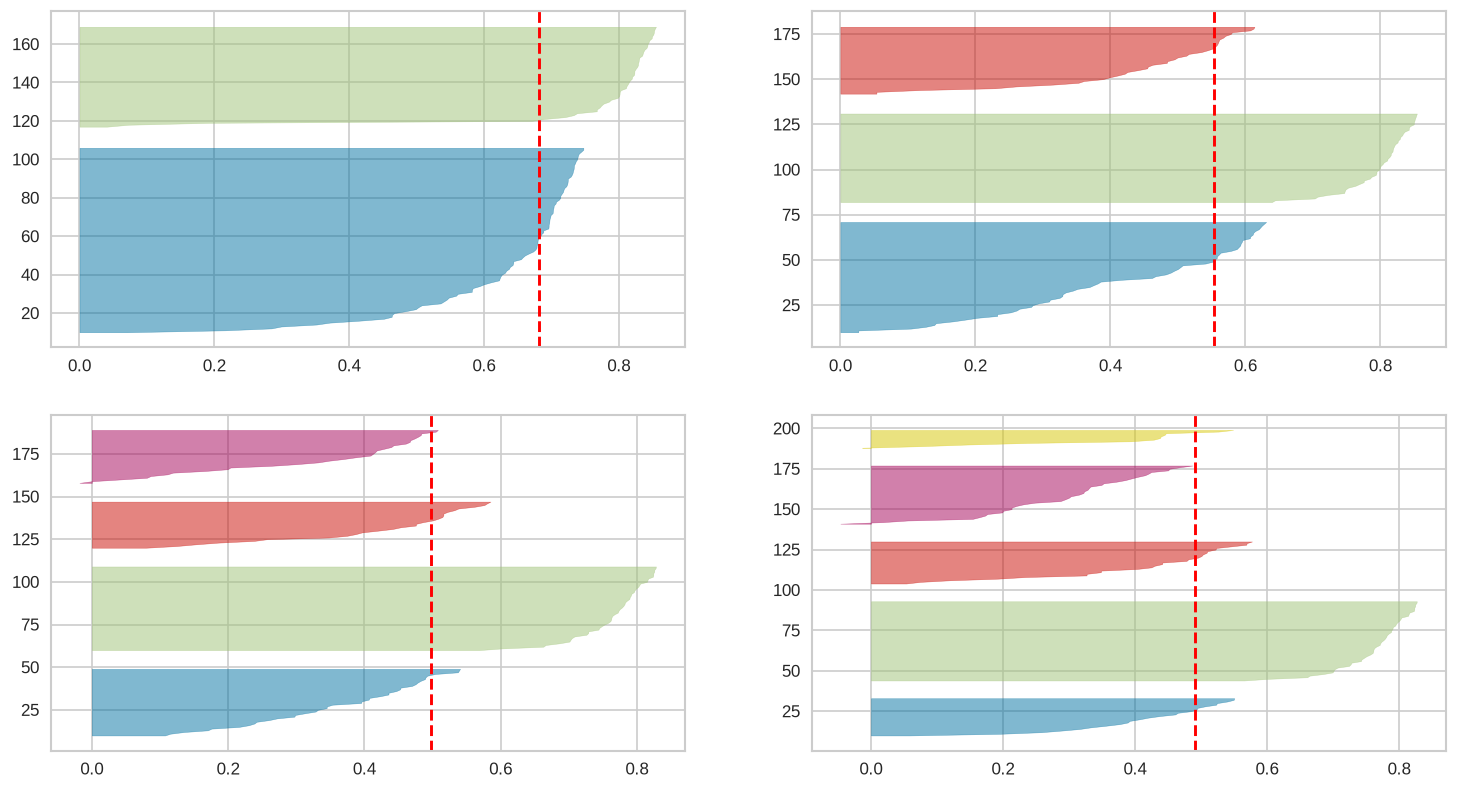

In [19]:
from yellowbrick.cluster import SilhouetteVisualizer
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(15,8))
scores = []
for i in [2, 3, 4, 5]:
    '''
    Create KMeans instance for different number of clusters
    '''
    km = KMeans(n_clusters=i, init='k-means++', n_init=10, max_iter=100, random_state=42)
    # Fit the KMeans model
    km.fit_predict(X)
    # Calculate Silhoutte Score
    score = silhouette_score(X, km.labels_, metric='euclidean')
    scores.append(score)
    q, mod = divmod(i, 2)
    '''
    Create SilhouetteVisualizer instance with KMeans instance
    Fit the visualizer
    '''
    visualizer = SilhouetteVisualizer(km, colors='yellowbrick', ax=ax[q-1][mod], force_model=True, is_fitted=True)
    visualizer.fit(X)

print({k: round(s, 3) for k, s in zip([2, 3, 4, 5], scores)})

منحنی SSE توضیح می‌دهد چرا قاعدهٔ آرنج قاعده نیست. کاهش تا $k=3$ تند است و بعد صاف می‌شود،
ولی هرگز متوقف نمی‌شود: در $k$ به‌قدر کافی بزرگ هر نقطه خوشهٔ خودش است و SSE دقیقاً صفر.

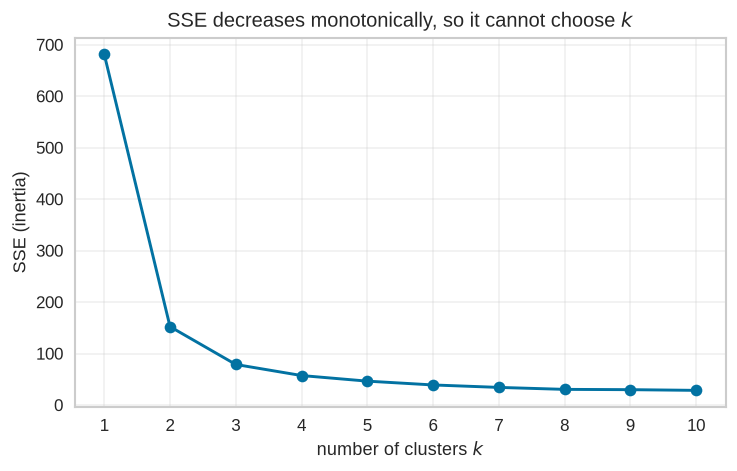

k =  1   SSE =   681.37
k =  2   SSE =   152.35
k =  3   SSE =    78.86
k =  4   SSE =    57.35
k =  5   SSE =    46.47
k =  6   SSE =    39.07
k =  7   SSE =    34.31
k =  8   SSE =    30.48
k =  9   SSE =    29.91
k = 10   SSE =    28.55


In [20]:
ks = range(1, 11)
sse = [KMeans(n_clusters=k, random_state=42).fit(X).inertia_ for k in ks]

plt.figure(figsize=(7, 4))
plt.plot(list(ks), sse, marker="o")
plt.xlabel("number of clusters $k$")
plt.ylabel("SSE (inertia)")
plt.title("SSE decreases monotonically, so it cannot choose $k$")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

for k, value in zip(ks, sse):
    print(f"k = {k:2d}   SSE = {value:8.2f}")

## انتخاب سنجهٔ درست

1. وقتی حقیقت‌مبنا در دسترس است از سنجه‌های بیرونی استفاده کنید
2. وقتی برچسبی نیست از سنجه‌های درونی استفاده کنید
3. برای ارزیابی استوار چند سنجه را با هم ببینید

به یاد داشته باشید که هیچ سنجهٔ واحدی همهٔ ماجرا را نمی‌گوید — سنجه‌های مختلف ممکن است برای
هدف‌های مختلف خوشه‌بندی مناسب‌تر باشند.

## مسئلهٔ تخصیص پشت تطبیق بیشینه

تطبیق بیشینه با وزن نمونه‌ای از **مسئلهٔ تخصیص** است: با جدول توافقی $r \times k$، تناظری
یک‌به‌یک میان سطرها و ستون‌ها انتخاب کن که وزن کل را بیشینه کند. برای جدول‌های مربعی الگوریتم
مجارستانی آن را دقیق حل می‌کند، همان چیزی که `scipy.optimize.linear_sum_assignment` پیاده کرده
است؛ برای جدول‌های مستطیلی همان روال تناظری بهینه برمی‌گرداند و سطرها یا ستون‌های اضافه بی‌جفت
می‌مانند، که وقتی $r \ne k$ دقیقاً همان چیزی است که می‌خواهیم.

همین مسئله هرجا دو مجموعه باید با قید یک‌به‌یک جفت شوند پیش می‌آید: دانشجو به مدرسه، داور به
مقاله، پرس‌وجو به سند، یا ویژگی به مؤلفه. فصل 17 زکی آن را برای اعتبارسنجی خوشه‌بندی بسط می‌دهد؛
بررسی کلی در همان کتاب است ({cite}`zaki2020data`).

### تطبیق با وزن بیشینه با `networkx`

جدول توافقی را می‌توان **گرافی دوبخشی** خواند: خوشه‌ها یک طرف، دسته‌ها طرف دیگر، و یالی با وزن
$n_{ij}$ هرجا $n_{ij} > 0$. آن‌گاه امتیاز تطبیق بیشینه وزن تطبیق با وزن بیشینهٔ آن گراف است.

`networkx.algorithms.matching.max_weight_matching` مسئلهٔ کلی را حل می‌کند؛ به گراف دوبخشی محدود
نیست، پس اگر گراف چنین یالی داشته باشد ممکن است یالی داخل یک قسمت به کار ببرد. اینجا هر یال یک
خوشه را به یک دسته می‌بندد، پس نتیجه تطبیقی از گراف دوبخشی است. صریحاً `weight="weight"` بدهید —
با پیش‌فرض `weight=None` وزن یال‌ها نادیده گرفته می‌شود و روال تطبیق با *بیشینهٔ کاردینالیتی*
برمی‌گرداند، که نسخهٔ پیشین این صفحه به اشتباه همین کار را می‌کرد.

matched pairs and weights:
  C2 - versicolor: 4
  virginica - C3: 50
  C1 - setosa: 30

matched weight = 84   match score = 0.560


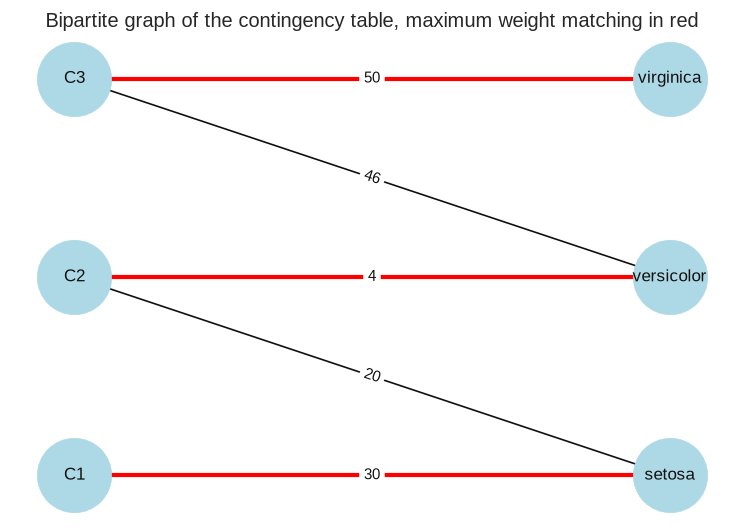

In [21]:
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

# the contingency table of the bad clustering, as a bipartite graph
table = np.array([[30, 0, 0], [20, 4, 0], [0, 46, 50]])
clusters = ["C1", "C2", "C3"]
classes = ["setosa", "versicolor", "virginica"]

G = nx.Graph()
G.add_nodes_from(clusters, bipartite=0)
G.add_nodes_from(classes, bipartite=1)
for i, cluster in enumerate(clusters):
    for j, cls in enumerate(classes):
        if table[i, j] > 0:
            G.add_edge(cluster, cls, weight=int(table[i, j]))

matching = nx.algorithms.matching.max_weight_matching(G, weight="weight")
total = sum(G[u][v]["weight"] for u, v in matching)

print("matched pairs and weights:")
for u, v in matching:
    print(f"  {u} - {v}: {G[u][v]['weight']}")
print(f"\nmatched weight = {total}   match score = {total / table.sum():.3f}")

pos = {**{n: (0, i) for i, n in enumerate(clusters)},
       **{n: (1, i) for i, n in enumerate(classes)}}
plt.figure(figsize=(6, 4))
nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=2000, font_size=10)
nx.draw_networkx_edges(G, pos, edgelist=list(matching), width=2.5, edge_color="red")
nx.draw_networkx_edge_labels(G, pos, font_size=9,
                             edge_labels={(u, v): G[u][v]["weight"] for u, v in G.edges})
plt.title("Bipartite graph of the contingency table, maximum weight matching in red")
plt.show()

## جمع‌بندی

* خوشه‌بندی به اعتبارسنجی نیاز دارد: بدون برچسب، «همگرا شد» هیچ چیزی دربارهٔ کیفیت نمی‌گوید.
* سنجه‌های بیرونی از جدول توافقی $r \times k$ یعنی $n_{ij}$ (سطر = خوشه، ستون = دسته) شروع
  می‌کنند که در $O(n)$ حساب می‌شود.
* خلوص مجموع بیشینه‌های سطرها است؛ خوش‌بین است، چون اجازه می‌دهد دو خوشه یک دسته را ادعا کنند.
* دقت، بازآوری و F نمای ستونی را اضافه می‌کنند؛ تطبیق بیشینه تناظر یک‌به‌یک را تحمیل می‌کند و یک
  مسئلهٔ تخصیص است (`linear_sum_assignment`).
* سنجه‌های دوبه‌دو توافق روی جفت نقطه‌ها را می‌شمارند: جاکارد $TN$ را نادیده می‌گیرد، رند همه را
  می‌شمارد و با $k$ باد می‌کند، ARI رند را برای شانس تصحیح می‌کند، NMI اطلاعات مشترک را می‌سنجد
  ولی تصحیح‌شده نیست.
* سنجه‌های درونی — سیلوئت، SSE، شکاف — فقط از داده استفاده می‌کنند؛ هیچ‌کدام تعداد واقعی خوشه‌ها
  را تعیین نمی‌کند و بهینه کردن یکی از آن‌ها می‌تواند پاسخ غلط بدهد.
* چند سنجه گزارش کنید و بگویید هر کدام به کدام پرسش پاسخ می‌دهد.